# 09 · Prediction-time leakage and feature assessment

**Goal:** classify every available column by whether it could be known when a shipment's risk is predicted, show
concretely how leakage would arise, list unresolved modelling decisions, and give a feature recommendation.

### The prediction timestamp is not defined
The data has no booking or prediction timestamp. Plausible choices:

| Option | Prediction made at | Consequence |
|---|---|---|
| A | booking (days before departure) | only static + calendar + forecast features; much weaker (notebook 08 H6: weather signal ≈ 0 at 72 h) |
| B | shortly before departure (EDA default: `departure_ts − 1 h`) | static + current port/weather/disruption state; strongest legitimate signal |
| C | at departure, updated en route | could add later port states; requires a rolling-prediction design |

This is an **unresolved product decision**. The EDA uses option B as a working convention. Every time-varying feature is
parameterised by `lag_hours` so the choice can be changed without re-engineering.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as ss

from cargomind_eda import io, stats, plotting as P
from cargomind_eda.config import CLASSES, CLASS_COLORS, INTERIM, THRESHOLDS

P.setup()
f = pd.read_pickle(INTERIM / "shipments_integrated.pkl")
sea = f[f.shipping_mode == "sea"].copy()
print(f.shape)

(9850, 240)


## I1. Column catalogue
Every column of the integrated dataset is assigned one category with a reason. Categories:

* **target** — the label;
* **outcome / leakage** — determined by or after arrival;
* **identifier / metadata** — keys and constants, no predictive meaning;
* **static (booking)** — fixed attributes of the shipment, route or port, known at booking;
* **schedule (booking)** — planned times and durations, known at booking;
* **calendar (safe)** — public-holiday features, published in advance;
* **as-of state (cutoff)** — port, weather, disruption and traffic state observed at or before the cutoff;
* **historical (point-in-time)** — outcomes of shipments that had *already arrived* by the cutoff;
* **future / leakage** — information from after the cutoff (`LEAK_*`);
* **needs investigation** — usable in principle, but timing, provenance or reliability is unresolved.

In [2]:
base = {
    "delay_status": ("target", "The label to predict."),
    "actual_delay_hours": ("outcome / leakage", "= actual_arrival_ts − expected_arrival_ts; defines the label exactly."),
    "actual_arrival_ts": ("outcome / leakage", "Known only on arrival; with expected_arrival_ts gives the label exactly."),
    "shipment_id": ("identifier / metadata", "Key; sequential IDs may encode creation order — never a feature."),
    "data_source": ("identifier / metadata", "Constant."), "is_synthetic": ("identifier / metadata", "Constant."),
    "route_id": ("static (booking)", "Booked route; better encoded via origin/destination/hub (notebook 06)."),
    "origin_port_id": ("static (booking)", "Booked origin."), "destination_port_id": ("static (booking)", "Booked destination."),
    "od_pair": ("static (booking)", "Same information as route_id."),
    "carrier": ("static (booking)", "Booked carrier; ~2 % filled during cleaning."),
    "shipping_mode": ("static (booking)", "Air ⇒ always On-Time here."),
    "cargo_type": ("static (booking)", "~3 % filled during cleaning."), "container_teu": ("static (booking)", "No association found."),
    "shipment_priority": ("static (booking)", "~2 % filled during cleaning."),
    "route_type": ("static (booking)", "From port_network."), "transshipment_port_id": ("static (booking)", "Hub; blank = direct (structural)."),
    "route_distance_km": ("static (booking)", "From port_network."), "planned_transit_hours": ("static (booking)", "Route plan; ≡ planned_duration_h for sea."),
    "departure_ts": ("schedule (booking)", "Planned departure. Assumes actual departure ≈ planned; a late departure would itself be information to verify."),
    "expected_arrival_ts": ("schedule (booking)", "Planned arrival; legitimate. ~2 % reconstructed during cleaning (from actual − delay), which is a subtle leakage path for those rows."),
    "planned_duration_h": ("schedule (booking)", "expected − departure."), "planned_vs_route_ratio": ("schedule (booking)", "≈1 for sea; distinguishes air."),
    "cutoff_ts": ("identifier / metadata", "Analysis reference time."), "exp_arr_hour": ("identifier / metadata", "Join helper."),
    "dep_plus24": ("identifier / metadata", "Join helper (leak measurement)."), "traffic_day": ("identifier / metadata", "Join helper."),
    "dep_local_date": ("identifier / metadata", "Join helper."), "exp_arr_local_date": ("identifier / metadata", "Join helper."),
    "dep_hour_utc": ("schedule (booking)", "No association found."), "dep_hour_local": ("schedule (booking)", "No association found."),
    "dep_dow_utc": ("schedule (booking)", "Negligible association."),
    "dep_day_index": ("needs investigation", "Days since data start: encodes *when*, not *why*. Will not extrapolate to future periods; exclude."),
    "route_departures_prev7d": ("as-of state (cutoff)", "Counts past departures; assumes the schedule is known. Weak."),
    "hol_calendar_covers_exp_arr": ("identifier / metadata", "Data-coverage flag, not a feature."),
}

def categorize(c):
    if c in base:
        return base[c]
    if c.startswith("LEAK_"):
        return ("future / leakage", "Uses observations after the cutoff (arrival-time conditions, next-24 h conditions, events starting later, or remaining event duration).")
    if c.startswith("filled_") or c in ("raw_label_was_Late", "outcome_not_observed_in_raw"):
        if any(k in c for k in ("actual", "delay_status", "Late", "outcome")):
            return ("outcome / leakage", "Lineage flag about the outcome columns; use for row filtering only.")
        return ("needs investigation", "Lineage flag (was missing in raw). Missingness at booking may be informative, but it reflects the cleaning process — use for sensitivity checks.")
    if c.endswith(("_region", "_capacity_teu_per_hour")):
        return ("static (booking)", "Port metadata.")
    if c.startswith("hist_"):
        return ("historical (point-in-time)", "Uses only shipments with actual_arrival_ts < cutoff.")
    if c.startswith("hol_"):
        return ("calendar (safe)", "Public holidays are published in advance. Unknown (not 'no holiday') after 26 Feb.")
    if c.startswith("tr_"):
        return ("needs investigation", "Previous complete day; safe in timing, but an exact aggregate of telemetry (redundant).")
    if "visibility" in c:
        return ("needs investigation", "Visibility for USLAX/CNSHA/LKCMB was filled during cleaning (not measured).")
    if c.startswith("dis_") and ("capacity_pct" in c or "max_sev" in c):
        return ("needs investigation", "Timing OK (event started before cutoff), but it is unknown whether severity / capacity impact is assessed at onset or recorded after the event.")
    if c.startswith("dis_"):
        return ("as-of state (cutoff)", "Event started at or before the cutoff and still active (or started within the prior 72 h).")
    if c.startswith(("o_", "d_", "h_", "wx_")):
        return ("as-of state (cutoff)", "Port telemetry / weather at or before the cutoff (snapshot or trailing 24 h).")
    return ("needs investigation", "Unclassified.")

cat = pd.DataFrame([(c, *categorize(c)) for c in f.columns], columns=["column", "category", "rationale"]).set_index("column")
print(cat.category.value_counts().to_string())

category
as-of state (cutoff)          130
needs investigation            32
static (booking)               19
future / leakage               17
historical (point-in-time)     12
identifier / metadata          10
schedule (booking)              7
outcome / leakage               7
calendar (safe)                 5
target                          1


In [3]:
scr = pd.read_csv(ROOT / "reports" / "tables" / "08_numeric_feature_screen_sea.csv", index_col=0)
cat = cat.join(scr[["cliff_At-Risk_vs_On-Time", "cliff_Critical_vs_On-Time", "spearman_rho_delay_h", "mutual_info"]])
cat["pct_missing"] = f.isna().mean().mul(100).round(1)
P.save_table(cat, "09_feature_catalog")
with pd.option_context("display.max_rows", 300, "display.max_colwidth", 120):
    display(cat[cat.category.isin(["target", "outcome / leakage", "future / leakage", "needs investigation"])].drop(columns=["mutual_info"]).round(3))

,category,rationale,cliff_At-Risk_vs_On-Time,cliff_Critical_vs_On-Time,spearman_rho_delay_h,pct_missing
column,,,,,,
actual_arrival_ts,outcome / leakage,Known only on arrival; with expected_arrival_ts gives the label exactly.,NaN,NaN,NaN,0
actual_delay_hours,outcome / leakage,= actual_arrival_ts − expected_arrival_ts; defines the label exactly.,NaN,NaN,NaN,0
delay_status,target,The label to predict.,NaN,NaN,NaN,0
dep_day_index,needs investigation,"Days since data start: encodes *when*, not *why*. Will not extrapolate to future periods; exclude.",-0.021,-0.065,-0.041,0
wx_o_visibility_m,needs investigation,Visibility for USLAX/CNSHA/LKCMB was filled during cleaning (not measured).,-0.002,-0.058,-0.022,0
wx_o_visibility_min24,needs investigation,Visibility for USLAX/CNSHA/LKCMB was filled during cleaning (not measured).,-0.118,-0.407,-0.229,0
wx_d_visibility_m,needs investigation,Visibility for USLAX/CNSHA/LKCMB was filled during cleaning (not measured).,-0.025,-0.052,-0.028,0
wx_d_visibility_min24,needs investigation,Visibility for USLAX/CNSHA/LKCMB was filled during cleaning (not measured).,-0.033,-0.153,-0.08,0
wx_h_visibility_m,needs investigation,Visibility for USLAX/CNSHA/LKCMB was filled during cleaning (not measured).,0.025,0.033,0.023,62.7


## I2. How leakage would show up — concrete demonstrations

### (a) Outcome columns reproduce the label exactly

In [4]:
recon = pd.cut(f.actual_delay_hours, [-np.inf, 12, 48, np.inf], labels=CLASSES)
print("accuracy of label reconstructed from actual_delay_hours:", (recon.astype(str) == f.delay_status.astype(str)).mean())
d2 = (f.actual_arrival_ts - f.expected_arrival_ts).dt.total_seconds() / 3600
print("accuracy reconstructed from actual_arrival_ts − expected_arrival_ts:",
      (pd.cut(d2, [-np.inf, 12, 48, np.inf], labels=CLASSES).astype(str) == f.delay_status.astype(str)).mean())

accuracy of label reconstructed from actual_delay_hours: 1.0
accuracy reconstructed from actual_arrival_ts − expected_arrival_ts: 1.0


### (b) Naive target encoding vs point-in-time history
A common mistake is to encode categories by their delay rate computed over the full dataset. That rate includes each
shipment's own outcome and future outcomes.

In [5]:
rows = []
for key in ["route_id", "carrier", "origin_port_id", "destination_port_id"]:
    naive = sea.groupby(key).actual_delay_hours.transform("mean")
    pit = sea[f"hist_{key}_mean_delay_h"]
    rows.append({"group": key,
                 "naive full-data encoding ρ": ss.spearmanr(naive, sea.actual_delay_hours)[0],
                 "point-in-time history ρ": ss.spearmanr(pit, sea.actual_delay_hours, nan_policy="omit")[0],
                 "naive δ Crit vs OT": stats.numeric_vs_target(sea.assign(_n=naive), "_n")["cliff_Critical_vs_On-Time"],
                 "PIT δ Crit vs OT": stats.numeric_vs_target(sea, f"hist_{key}_mean_delay_h")["cliff_Critical_vs_On-Time"]})
pd.DataFrame(rows).set_index("group").round(3)

,naive full-data encoding ρ,point-in-time history ρ,naive δ Crit vs OT,PIT δ Crit vs OT
group,,,,
route_id,0.322,0.084,0.428,0.076
carrier,0.187,0.134,0.192,0.188
origin_port_id,0.211,0.047,0.312,0.069
destination_port_id,0.128,0.046,0.15,0.065


For route, origin and destination, the naive encoding looks 4–6× stronger than the point-in-time version (route δ 0.43 vs
0.08; origin 0.31 vs 0.07). It averages over the *same weeks and episodes* as the shipment, including the shipment itself.
A deployed model can only compute the point-in-time version. **Carrier is the exception** (0.19 vs 0.19): carrier
performance is stable over time, so its history is a legitimate, robust signal. Use point-in-time / out-of-time encodings only.

### (c) Shared-episode leakage under a random split
Shipments departing from the same port within a few hours share the same port state. A random train/test split puts these
"siblings" on both sides.

In [6]:
rng = np.random.default_rng(0)
test = rng.random(len(sea)) < 0.2
tr, te = sea[~test], sea[test]
sib = te[["origin_port_id", "departure_ts"]].merge(tr[["origin_port_id", "departure_ts", "delay_status"]], on="origin_port_id", suffixes=("", "_tr"))
sib = sib[(sib.departure_ts - sib.departure_ts_tr).abs() <= pd.Timedelta("6h")]
share = sib.drop_duplicates(["origin_port_id", "departure_ts"]).shape[0] / te.drop_duplicates(["origin_port_id", "departure_ts"]).shape[0]
print(f"random 80/20 split: {share*100:.1f}% of test (origin, departure-time) slots have a training shipment from the same origin within ±6 h")
# How similar are sibling outcomes?
s2 = sea.sort_values(["origin_port_id", "departure_ts"])
same_slot = s2.groupby(["origin_port_id", "departure_ts"]).delay_status.agg(lambda x: x.nunique() == 1)
multi = s2.groupby(["origin_port_id", "departure_ts"]).size() > 1
print(f"(origin, departure hour) slots with ≥2 sea shipments: {multi.sum()}; share with all-identical class: {same_slot[multi].mean()*100:.1f}%")
base_rate = (sea.delay_status.value_counts(normalize=True) ** 2).sum()
print(f"(chance of two random shipments sharing a class: {base_rate*100:.1f}%)")

random 80/20 split: 99.8% of test (origin, departure-time) slots have a training shipment from the same origin within ±6 h
(origin, departure hour) slots with ≥2 sea shipments: 2397; share with all-identical class: 47.2%
(chance of two random shipments sharing a class: 40.2%)


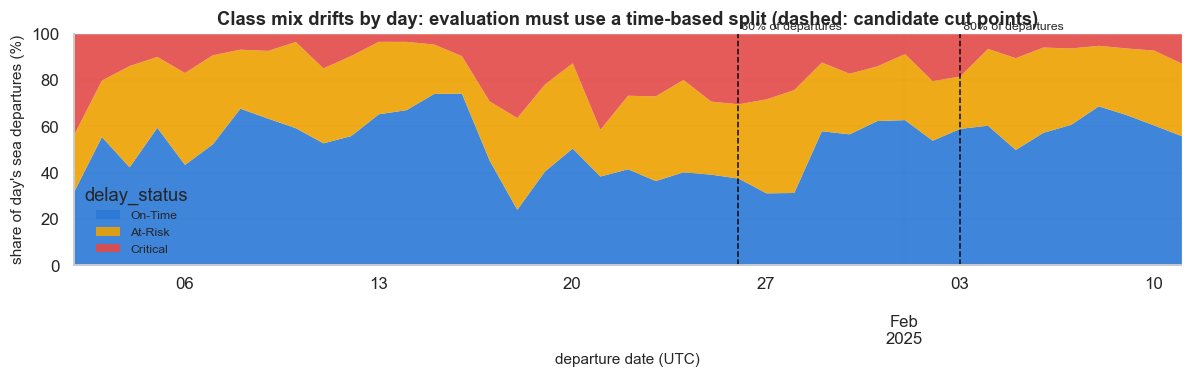

In [7]:
fig, ax = plt.subplots(figsize=(11, 3.6))
day = sea.groupby(sea.departure_ts.dt.floor("D")).delay_status.value_counts(normalize=True).unstack()[CLASSES] * 100
day.plot.area(ax=ax, color=P.PALETTE, linewidth=0, alpha=0.9)
for q in [0.6, 0.8]:
    cut = sea.departure_ts.quantile(q)
    ax.axvline(cut, color="#0b0b0b", ls="--", lw=1)
    ax.text(cut, 102, f" {int(q*100)}% of departures", fontsize=8)
ax.set_ylim(0, 100)
ax.set_ylabel("share of day's sea departures (%)")
ax.set_xlabel("departure date (UTC)")
ax.set_title("Class mix drifts by day: evaluation must use a time-based split (dashed: candidate cut points)")
ax.legend(title="delay_status", loc="lower left", fontsize=8)
P.save(fig, "09_class_mix_by_day_split_points")

Almost every test slot (99.8 %) has a training sibling from the same origin within ±6 h. Siblings' classes agree more often
than chance (47 % vs 40 %), but they are far from identical. The main risk is not copying labels: a random split lets a model
learn *episode-specific* patterns (e.g. "NLRTM in the week of 18 Jan") that will not recur, and rewards features such as
date indices. A time-based split is required to measure generalisation to new episodes.

### (d) Target-label horizon: an extra time-split subtlety
A shipment's label is known only at `actual_arrival_ts`. If the training set is "shipments departing before date *T*",
some of those have not arrived by *T* and their labels would not exist yet in a real retraining run.

In [8]:
for q in [0.6, 0.7, 0.8]:
    T = sea.departure_ts.quantile(q)
    trn = sea[sea.departure_ts < T]
    print(f"cut at {T.date()}: train departures {len(trn)}, of which not yet arrived at cut: {(trn.actual_arrival_ts >= T).sum()} "
          f"({(trn.actual_arrival_ts >= T).mean()*100:.0f}%) — mostly long voyages and delayed ones: "
          f"{(trn[trn.actual_arrival_ts >= T].delay_status != 'On-Time').mean()*100:.0f}% delayed vs {(trn.delay_status != 'On-Time').mean()*100:.0f}% overall")

cut at 2025-01-26: train departures 5608, of which not yet arrived at cut: 2740 (49%) — mostly long voyages and delayed ones: 57% delayed vs 49% overall
cut at 2025-01-30: train departures 6543, of which not yet arrived at cut: 2790 (43%) — mostly long voyages and delayed ones: 60% delayed vs 50% overall
cut at 2025-02-03: train departures 7474, of which not yet arrived at cut: 2835 (38%) — mostly long voyages and delayed ones: 59% delayed vs 49% overall


Training only on shipments whose label is known by the cut would bias the training data towards short and on-time voyages.
Training on all shipments that departed before the cut uses labels from the future. For offline evaluation, use a gap
(purge) between train and test periods. Then decide explicitly how a production retraining job treats in-transit shipments.

## I3. Unresolved modelling decisions (documented, not invented)

1. **Prediction timestamp** (booking vs pre-departure vs en route). Determines which state features are allowed; the signal
   depends strongly on it (notebook 08 H6).
2. **Semantics of `ts_hour`** (start or end of the hour) — determines whether the record at `departure_ts − 1 h` is complete.
   The 1 h lag is safe under both readings.
3. **When disruption attributes become known.** Is `severity` / `affected_capacity_pct` assigned at onset or after the fact?
   If after, those columns leak. `event_end` and total duration certainly leak for ongoing events.
4. **Actual vs planned departure.** Only `departure_ts` exists. If it is the *actual* departure, a delayed departure would
   already be known before the arrival delay. Its interpretation affects whether delay is measured against an updated ETA.
5. **Filled values from cleaning.** 295 shipments have outcomes that were never observed in raw. Exclude them from training
   and evaluation (recommended). Decide whether filled input attributes (carrier/cargo/priority/TEU; 12.5 % of shipments
   have ≥1) are acceptable. Visibility at USLAX/CNSHA/LKCMB and ~1.5k telemetry cells are reconstructed.
6. **Air shipments** — rule-based (always On-Time here) or part of the model?
7. **Ordinal vs nominal treatment** of the three classes and the cost of each confusion (Critical predicted On-Time vs others).
8. **Label horizon / retraining policy** for in-transit shipments (I2-d).

## I4. Feature recommendation

In [9]:
rec = pd.DataFrame([
    ("Origin disruption state", "dis_o_active_any / dis_o_active_max_sev, dis_o_active_weather|strike|congestion, dis_o_active_hours_elapsed", "use", "strongest signal; pick one of any/n/max_sev (ρ>0.99); severity/capacity pending decision 3"),
    ("Origin congestion", "o_anchor_mean24, o_container_dwell_hours (or o_dwell_mean24), o_vessel_time_in_port_hours", "use", "medium–large δ; drop redundant snapshot/max variants"),
    ("Origin utilization", "o_util_max24 together with o_port_utilization_pct", "use with care", "non-monotonic; low current utilization can mean lost capacity"),
    ("Origin weather (24 h)", "wx_o_gust_max24, wx_o_precip_sum24, wx_o_thunderstorm_hours24, pressure anomaly", "use", "drop wind speed (≈ gusts); visibility only if decision 5 accepts filled values"),
    ("Route structure", "route_type, transshipment hub, origin, destination (per role)", "use", "explains route-level risk (R² 0.91); avoid 90-level route_id"),
    ("Hub state", "h_util_mean24, h_anchor_mean24, dis_h_active_any", "use (structural NA)", "only for transshipment routes; encode 'no hub' explicitly"),
    ("Shipment attributes", "carrier, shipment_priority, cargo_type, shipping_mode", "use", "independent of route; air rule"),
    ("Calendar", "hol_o_days_to_nearest / hol_o_within_2d, hol_h_days_in_voyage, hol_d_within_2d_of_exp_arr", "use", "safe; destination holiday unknown after 26 Feb"),
    ("Destination state at departure", "d_anchor_mean24, d_util_mean24, dis_d_active_any", "optional", "weak"),
    ("Point-in-time history", "hist_carrier_* (use); hist_route/origin/destination_* (optional)", "use / optional", "carrier history is stable (δ 0.19); others weak in this short window; never naive full-data encodings"),
    ("Traffic history", "tr_*", "exclude", "exact daily aggregate of telemetry (redundant)"),
    ("Customs hold, equipment availability, TEU, departure hour/weekday, route frequency", "o_customs_*, o_equip_*, container_teu, dep_hour_*, dep_dow_utc, route_departures_prev7d", "deprioritise", "no meaningful association found"),
    ("Time index", "dep_day_index, departure date", "exclude", "encodes period, will not generalise"),
    ("Outcome & future", "actual_arrival_ts, actual_delay_hours, delay_status, LEAK_*", "exclude", "leakage"),
], columns=["group", "columns", "recommendation", "reason"])
P.save_table(rec.set_index("group"), "09_feature_recommendation")
with pd.option_context("display.max_colwidth", 140):
    display(rec)

,group,columns,recommendation,reason
0,Origin disruption state,"dis_o_active_any / dis_o_active_max_sev, dis_o_active_weather|strike|congestion, dis_o_active_hours_elapsed",use,strongest signal; pick one of any/n/max_sev (ρ>0.99); severity/capacity pending decision 3
1,Origin congestion,"o_anchor_mean24, o_container_dwell_hours (or o_dwell_mean24), o_vessel_time_in_port_hours",use,medium–large δ; drop redundant snapshot/max variants
2,Origin utilization,o_util_max24 together with o_port_utilization_pct,use with care,non-monotonic; low current utilization can mean lost capacity
3,Origin weather (24 h),"wx_o_gust_max24, wx_o_precip_sum24, wx_o_thunderstorm_hours24, pressure anomaly",use,drop wind speed (≈ gusts); visibility only if decision 5 accepts filled values
4,Route structure,"route_type, transshipment hub, origin, destination (per role)",use,explains route-level risk (R² 0.91); avoid 90-level route_id
5,Hub state,"h_util_mean24, h_anchor_mean24, dis_h_active_any",use (structural NA),only for transshipment routes; encode 'no hub' explicitly
6,Shipment attributes,"carrier, shipment_priority, cargo_type, shipping_mode",use,independent of route; air rule
7,Calendar,"hol_o_days_to_nearest / hol_o_within_2d, hol_h_days_in_voyage, hol_d_within_2d_of_exp_arr",use,safe; destination holiday unknown after 26 Feb
8,Destination state at departure,"d_anchor_mean24, d_util_mean24, dis_d_active_any",optional,weak
9,Point-in-time history,hist_carrier_* (use); hist_route/origin/destination_* (optional),use / optional,carrier history is stable (δ 0.19); others weak in this short window; never naive full-data encodings


### Additional feature engineering worth testing
* **Backlog / pressure indicators:** anchor-queue trend (Δ over 6–24 h), arrivals − departures cumulative over 24–72 h, utilization
  saturation streak (consecutive hours at 100 %), and dwell trend. These capture the build-up visible in notebook 04.
* **Disruption context:** hours since the most recent event ended (recovery phase), events in the last 7 days, capacity loss ×
  elapsed-time interaction.
* **Exposure along the route:** hub state at the *expected hub-call time* using forecasts (if a forecast feed exists); planned
  hub dwell.
* **Weather persistence:** max gust over 6/12/48 h windows; storm flag; pressure tendency. Encode wind direction as sin/cos if used.
* **Holiday windows:** local-time days to/from the nearest holiday at origin, hub and destination; multi-day festival flags.
* **Relative features:** port metrics as deviations from the port's own trailing baseline (z-scores) to remove port-scale effects.
* **Point-in-time target history** on longer windows once more data exists, with arrival-time-aware cut-offs.

## I5. Readiness for modelling

**Ready, with conditions.**

* ✔ One clean row per shipment, keys and foreign keys consistent, timestamps uniformly UTC, hourly series complete.
* ✔ Strong, interpretable, *legitimately available* signal at a pre-departure cutoff: origin disruption and congestion state,
  origin weather, route structure, carrier/priority/cargo.
* ✔ Moderate class imbalance (≈ 55/30/15), manageable with class weights.
* ⚠ Exclude the 295 shipments whose outcomes were filled during cleaning (or prove the fill method is valid).
* ⚠ Fix the prediction timestamp (decision 1) before final feature selection. Signal strength depends on it.
* ⚠ Use time-based evaluation with a purge gap; random splits will overstate performance because of shared port episodes.
* ⚠ Treat air shipments separately (rule) or report metrics on sea shipments.
* ⚠ The data window is ~6 weeks, 10 ports, one season (incl. Spring Festival). Generalisation to other periods is untested.
  With only ~3 independent fortnights, performance estimates will be noisy.